# Trabajo Práctico 3: Aprendizaje No Supervisado
## Segmentación de clientes mayoristas con PCA, selección de variables y K-means

Objetivo: comparar tres representaciones del mismo conjunto de datos (variables originales, dos componentes principales y un subconjunto de variables no redundantes) para ver cómo cambia la calidad del agrupamiento con K-means, y decidir cuál es la más apropiada.

Estructura del notebook:
1. Dataset y preparación
2. PCA
3. Selección de variables por correlación
4. K-means sobre las tres versiones y comparación
5. Discusión y conclusiones

## A. Selección del dataset

Se usa el dataset público Wholesale Customers (UCI Machine Learning Repository, también disponible en Kaggle). Contiene 440 clientes de un distribuidor mayorista en Portugal y su gasto anual en distintas categorías de producto.

Cumplimiento de los criterios del enunciado:
- Hay 8 columnas, de las cuales 6 son variables continuas de gasto anual (dentro del rango de 5 a 10 variables numéricas).
- `Channel` (Horeca o Retail) y `Region` son códigos categóricos. Si se dejaran, K-means los trataría como magnitudes numéricas sin sentido, así que se excluyen del agrupamiento.
- No hay valores faltantes (se verifica abajo).

In [2]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import os

SEED = 42
os.makedirs('figures', exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')

raw = pd.read_csv('Wholesale customers data.csv')
print('Dimensiones:', raw.shape)
print('Valores faltantes:', int(raw.isna().sum().sum()))
raw.head()

Dimensiones: (440, 8)
Valores faltantes: 0


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## B. Preparación del dataset

### B.2 Variables seleccionadas y su relevancia

| Variable | Descripción | Relevancia |
|---|---|---|
| Fresh | Gasto anual en productos frescos | Distingue clientes de gastronomía y hotelería |
| Milk | Gasto anual en lácteos | Compra típica de comercios minoristas y de cafeterías |
| Grocery | Gasto anual en almacén | Mide el perfil de abastecimiento general |
| Frozen | Gasto anual en congelados | Indica necesidades de cadena de frío y restauración |
| Detergents_Paper | Gasto anual en detergentes y papel | Productos no alimenticios, asociados al comercio minorista |
| Delicassen | Gasto anual en delicatessen | Segmento de productos gourmet, de menor volumen |

Todas están en la misma unidad (unidades monetarias anuales), pero con escalas muy distintas, por lo que la estandarización es necesaria para que ninguna domine el cálculo de distancias.

In [3]:
vars_all = ['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen']
df = raw[vars_all].copy()
display(df.describe().T.round(1))

,count,mean,std,min,25%,50%,75%,max
Fresh,440.0,12000.3,12647.3,3.0,3127.8,8504.0,16933.8,112151.0
Milk,440.0,5796.3,7380.4,55.0,1533.0,3627.0,7190.2,73498.0
Grocery,440.0,7951.3,9503.2,3.0,2153.0,4755.5,10655.8,92780.0
Frozen,440.0,3071.9,4854.7,25.0,742.2,1526.0,3554.2,60869.0
Detergents_Paper,440.0,2881.5,4767.9,3.0,256.8,816.5,3922.0,40827.0
Delicassen,440.0,1524.9,2820.1,3.0,408.2,965.5,1820.2,47943.0


Las medias son bastante mayores que las medianas y los máximos son muy altos respecto del tercer cuartil: las distribuciones tienen asimetría positiva fuerte y valores extremos (clientes muy grandes). Esto se tendrá en cuenta al interpretar K-means, que es sensible a los atípicos.

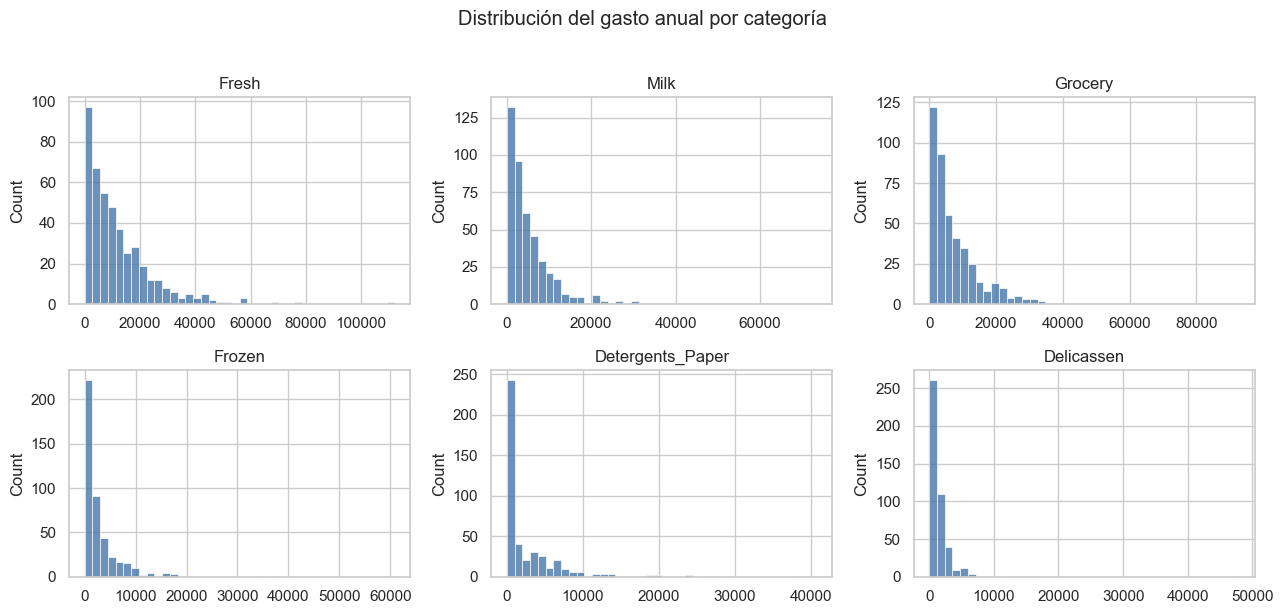

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, v in zip(axes.ravel(), vars_all):
    sns.histplot(df[v], bins=40, ax=ax, color='#3b6ea5')
    ax.set_title(v); ax.set_xlabel('')
plt.suptitle('Distribución del gasto anual por categoría', y=1.02)
plt.tight_layout()
plt.savefig('figures/01_distribuciones.png', dpi=150, bbox_inches='tight')
plt.show()

### B.1 Estandarización

Se aplica `StandardScaler` (media 0, desvío 1 por variable) sobre las seis variables.

In [5]:
scaler = StandardScaler()
X = scaler.fit_transform(df)
X_df = pd.DataFrame(X, columns=vars_all)
print(X_df.mean().round(6).to_dict())
print(X_df.std(ddof=0).round(6).to_dict())

{'Fresh': -0.0, 'Milk': 0.0, 'Grocery': -0.0, 'Frozen': 0.0, 'Detergents_Paper': 0.0, 'Delicassen': -0.0}
{'Fresh': 1.0, 'Milk': 1.0, 'Grocery': 1.0, 'Frozen': 1.0, 'Detergents_Paper': 1.0, 'Delicassen': 1.0}


## C. Reducción de dimensionalidad con PCA

### C.1 y C.2 PCA y scree plot

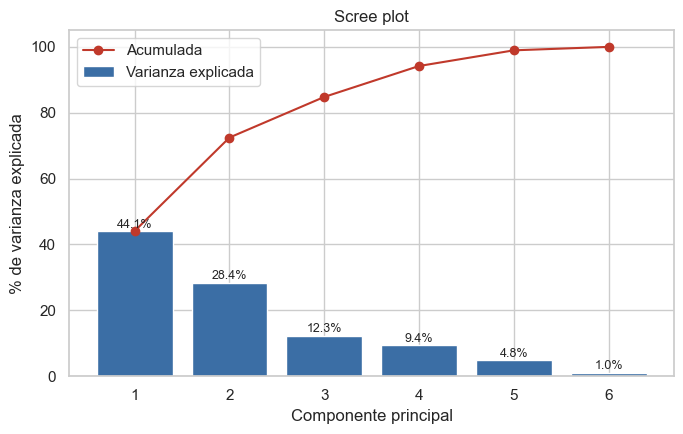

     Varianza (%)  Acumulada (%)
PC1          44.1           44.1
PC2          28.4           72.5
PC3          12.3           84.8
PC4           9.4           94.2
PC5           4.8           99.0
PC6           1.0          100.0


In [6]:
pca_full = PCA(random_state=SEED).fit(X)
var_exp = pca_full.explained_variance_ratio_ * 100
cum = np.cumsum(var_exp)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(range(1, 7), var_exp, color='#3b6ea5', label='Varianza explicada')
ax.plot(range(1, 7), cum, 'o-', color='#c0392b', label='Acumulada')
for i, (v, c) in enumerate(zip(var_exp, cum), start=1):
    ax.text(i, v + 1, f'{v:.1f}%', ha='center', fontsize=9)
ax.set_xlabel('Componente principal'); ax.set_ylabel('% de varianza explicada')
ax.set_title('Scree plot'); ax.legend(); ax.set_ylim(0, 105)
plt.tight_layout(); plt.savefig('figures/02_scree_plot.png', dpi=150)
plt.show()

print(pd.DataFrame({'Varianza (%)': var_exp.round(1), 'Acumulada (%)': cum.round(1)},
                   index=[f'PC{i}' for i in range(1, 7)]))

Interpretación: PC1 explica cerca del 44% y PC2 cerca del 28%; juntas retienen alrededor del 72% de la varianza total. Después de PC2 la caída es clara (PC3 aporta cerca del 12%), de modo que el codo del scree plot respalda quedarse con dos componentes. Se pierde información (28%), pero a cambio se obtiene una representación que se puede graficar.

### C.3 Reducción a dos componentes y cargas

Las cargas indican cómo se construye cada componente a partir de las variables originales.

,PC1,PC2
Fresh,0.04,0.53
Milk,0.55,0.08
Grocery,0.58,-0.15
Frozen,0.05,0.61
Detergents_Paper,0.55,-0.26
Delicassen,0.25,0.50


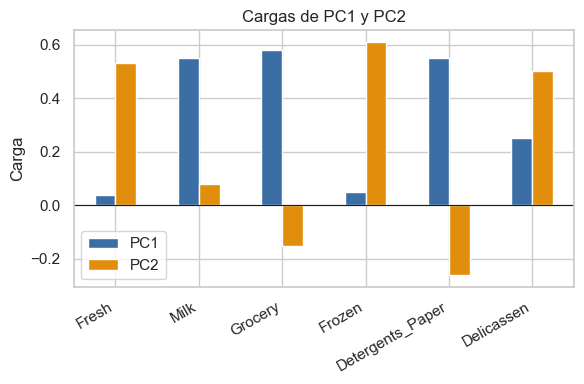

In [7]:
pca2 = PCA(n_components=2, random_state=SEED)
Z = pca2.fit_transform(X)
loadings = pd.DataFrame(pca2.components_.T, index=vars_all, columns=['PC1','PC2']).round(2)
display(loadings)

fig, ax = plt.subplots(figsize=(6, 4))
loadings.plot(kind='bar', ax=ax, color=['#3b6ea5', '#e08e0b'])
ax.axhline(0, color='k', lw=.8); ax.set_title('Cargas de PC1 y PC2'); ax.set_ylabel('Carga')
plt.xticks(rotation=30, ha='right'); plt.tight_layout()
plt.savefig('figures/03_cargas_pca.png', dpi=150); plt.show()

Lectura de los componentes:
- PC1 combina positivamente Grocery, Detergents_Paper y Milk (cargas cercanas a 0.55). Es un eje de consumo de productos de almacén, limpieza y lácteos, típico de comercio minorista.
- PC2 está dominado por Frozen, Fresh y Delicassen, y contrasta con Detergents_Paper. Es un eje ligado a productos frescos y congelados, típico de gastronomía.

### C.4 Diagrama de dispersión en el plano de las dos primeras componentes

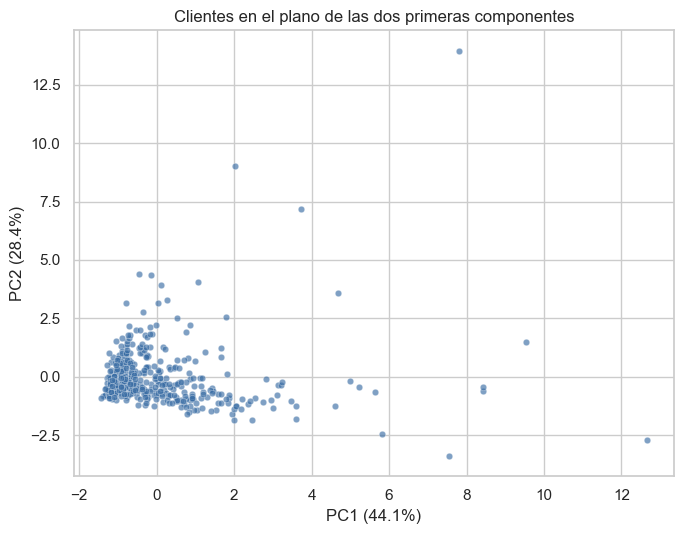

In [8]:
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(Z[:, 0], Z[:, 1], s=22, alpha=.65, color='#3b6ea5', edgecolor='white', lw=.3)
ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}%)'); ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}%)')
ax.set_title('Clientes en el plano de las dos primeras componentes')
plt.tight_layout(); plt.savefig('figures/04_dispersion_pca.png', dpi=150); plt.show()

Análisis: la mayor parte de los clientes forma una nube densa cerca del origen, y un grupo menor de clientes se dispersa hacia valores altos de PC1 y de PC2. No se ven grupos separados por zonas vacías: el patrón es más bien un núcleo compacto con una cola larga hacia valores extremos, consecuencia de la asimetría de los datos. Esto anticipa que K-means va a separar sobre todo a los clientes de gasto muy alto del resto.

## D. Selección de variables

### D.1 Análisis de correlación

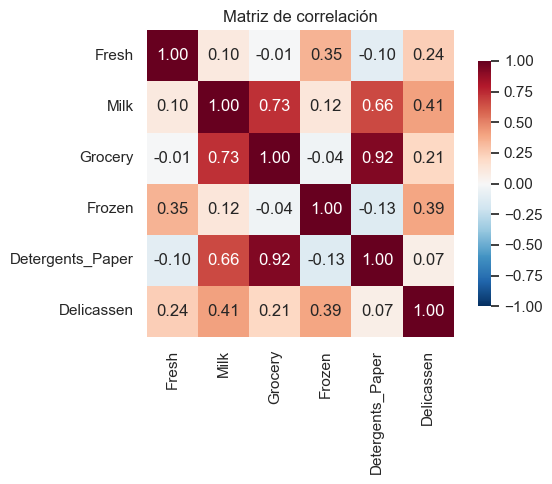

,var1,var2,r
10,Grocery,Detergents_Paper,0.92
5,Milk,Grocery,0.73
7,Milk,Detergents_Paper,0.66


In [9]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={'shrink': .8}, ax=ax)
ax.set_title('Matriz de correlación')
plt.tight_layout(); plt.savefig('figures/05_correlacion.png', dpi=150); plt.show()

pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename('r').reset_index())
pares.columns = ['var1','var2','r']
display(pares.loc[pares.r.abs() > 0.6].sort_values('r', ascending=False).round(2))

### D.2 Criterio de selección

Criterio: se consideran redundantes los pares con correlación en valor absoluto superior a 0.70, porque aportan casi la misma información y, en K-means, terminan pesando doble en la distancia.

Pares por encima del umbral:
- Grocery y Detergents_Paper (r = 0.92)
- Milk y Grocery (r = 0.73)

Milk y Detergents_Paper (r = 0.66) quedan por debajo del umbral, pero están conectadas a través de Grocery: las tres forman un bloque que se mueve junto (es el mismo bloque que construye PC1). Se conserva Milk como representante del bloque y se eliminan Grocery y Detergents_Paper, que son las que tienen las correlaciones más altas con el resto del bloque. Se elige Milk porque es la variable del bloque con menor correlación promedio con las otras dos (0.70, frente a 0.83 de Grocery y 0.79 de Detergents_Paper), es decir, la que menos información duplica, y además conserva un vínculo moderado con Delicassen (r = 0.41).

Variables finales: Fresh, Milk, Frozen y Delicassen. Costo de la decisión: se pierde la información propia de Grocery y Detergents_Paper, que son justamente las que más cargan en PC1.

In [10]:
vars_sel = ['Fresh', 'Milk', 'Frozen', 'Delicassen']
X_sel = StandardScaler().fit_transform(df[vars_sel])
print('Variables retenidas:', vars_sel)
print('Correlación máxima entre las retenidas:',
      df[vars_sel].corr().where(~np.eye(4, dtype=bool)).abs().max().max().round(2))

Variables retenidas: ['Fresh', 'Milk', 'Frozen', 'Delicassen']
Correlación máxima entre las retenidas: 0.41


## E. Agrupamiento con K-means y comparación

### E.1 y E.2 K-means para K entre 2 y 6 sobre las tres versiones

Para cada versión se calculan la inercia (método del codo) y el silhouette score. Se usa `n_init=10` y `random_state=42` para que los resultados sean reproducibles.

Advertencia metodológica: el silhouette y la inercia se calculan en espacios de distinta dimensión (6, 2 y 4 variables). La inercia en particular no es comparable entre enfoques (depende de la escala y de la cantidad de dimensiones), por lo que se usa solo para ubicar el codo dentro de cada enfoque. El silhouette está acotado entre -1 y 1 y se puede mirar entre enfoques, pero con cautela, porque medir distancias en 2 dimensiones es distinto a medirlas en 6.

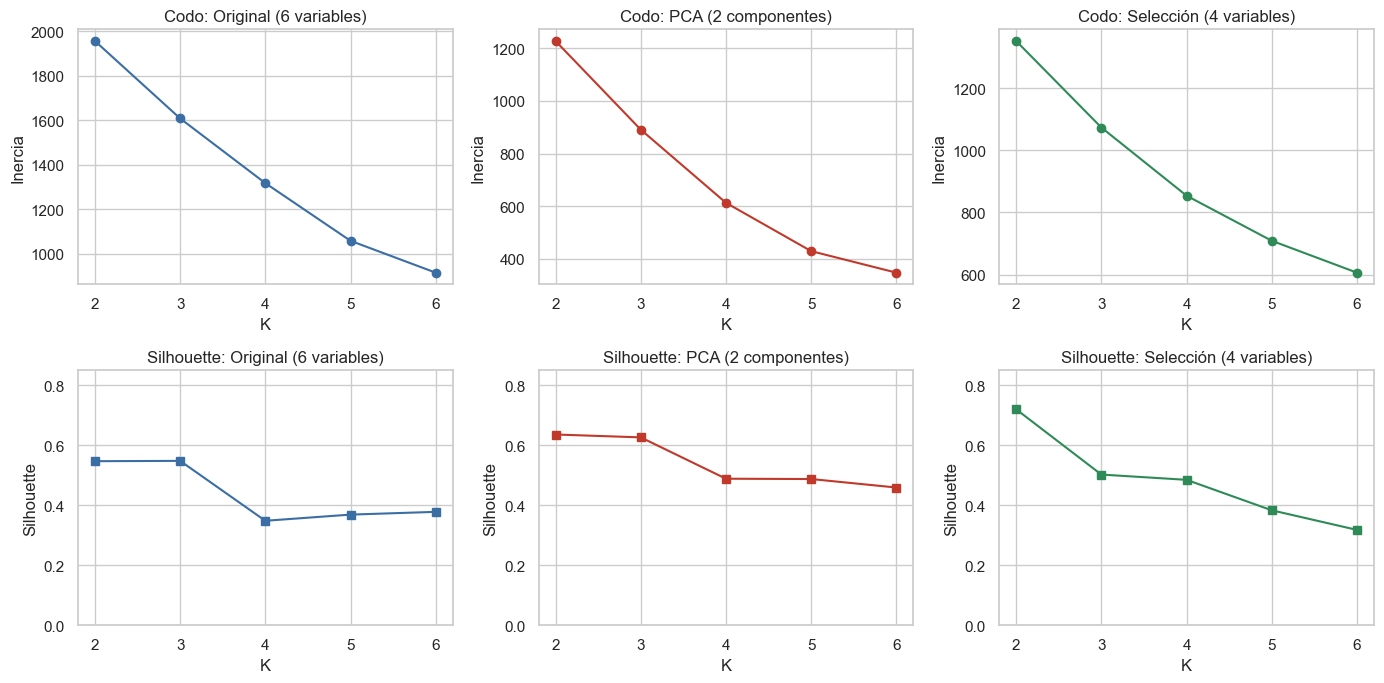

In [11]:
datasets = {
    'Original (6 variables)': X,
    'PCA (2 componentes)': Z,
    'Selección (4 variables)': X_sel,
}
Ks = range(2, 7)
rows, labels_store = [], {}
for name, A in datasets.items():
    for k in Ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(A)
        lab = km.labels_
        sizes = np.bincount(lab)
        rows.append({'Enfoque': name, 'K': k,
                     'Inercia': km.inertia_,
                     'Silhouette': silhouette_score(A, lab),
                     'Cluster más chico': sizes.min(),
                     'Cluster más grande': sizes.max()})
        labels_store[(name, k)] = lab
res = pd.DataFrame(rows)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
colors = ['#3b6ea5', '#c0392b', '#2e8b57']
for j, (name, _) in enumerate(datasets.items()):
    sub = res[res.Enfoque == name]
    axes[0, j].plot(sub.K, sub.Inercia, 'o-', color=colors[j])
    axes[0, j].set_title(f'Codo: {name}'); axes[0, j].set_xlabel('K'); axes[0, j].set_ylabel('Inercia')
    axes[1, j].plot(sub.K, sub.Silhouette, 's-', color=colors[j])
    axes[1, j].set_title(f'Silhouette: {name}'); axes[1, j].set_xlabel('K'); axes[1, j].set_ylabel('Silhouette')
    axes[1, j].set_ylim(0, .85)
plt.tight_layout(); plt.savefig('figures/06_codo_silhouette.png', dpi=150); plt.show()

### E.3 Tabla comparativa por enfoque y valor de K

In [12]:
tabla = res.copy()
tabla['Inercia'] = tabla['Inercia'].round(0).astype(int)
tabla['Silhouette'] = tabla['Silhouette'].round(3)
display(tabla.set_index(['Enfoque', 'K']))

pivot = res.pivot(index='K', columns='Enfoque', values='Silhouette').round(3)
display(pivot[list(datasets.keys())])
res.to_csv('resultados_kmeans.csv', index=False)

Inercia  Silhouette  Cluster más chico  \
Enfoque                 K                                           
Original (6 variables)  2     1956       0.547                 51   
                        3     1608       0.548                  2   
                        4     1318       0.348                  5   
                        5     1059       0.369                  1   
                        6      916       0.378                  1   
PCA (2 componentes)     2     1228       0.636                 45   
                        3      891       0.627                  3   
                        4      613       0.489                  3   
                        5      429       0.488                  3   
                        6      347       0.459                  3   
Selección (4 variables) 2     1352       0.720                 19   
                        3     1073       0.503                  1   
                        4      854       0.485                  1   
                        5      709       0.383                  1   
                        6      606       0.318                  1   

                           Cluster más grande  
Enfoque                 K                      
Original (6 variables)  2                 389  
                        3                 393  
                        4                 315  
                        5                 270  
                        6                 280  
PCA (2 componentes)     2                 395  
                        3                 393  
                        4                 329  
                        5                 266  
                        6                 229  
Selección (4 variables) 2                 421  
                        3                 366  
                        4                 350  
                        5                 305  
                        6                 269

Enfoque,Original (6 variables),PCA (2 componentes),Selección (4 variables)
K,,,
2,0.547,0.636,0.720
3,0.548,0.627,0.503
4,0.348,0.489,0.485
5,0.369,0.488,0.383
6,0.378,0.459,0.318


### E.4 Comparación de los tres enfoques

Los datos de la tabla permiten observar lo siguiente:

- Con las variables originales, el silhouette es relativamente alto en K=2 y K=3 y cae con K=4 en adelante. El codo no es nítido: la inercia baja de forma casi continua.
- Con PCA, el silhouette es más alto que con las variables originales en todos los K, y la inercia cae sin un codo muy marcado (el método del codo es poco concluyente en los tres enfoques, por eso el silhouette pesa más en la decisión). Que PCA mejore el silhouette era esperable: PCA descarta las dimensiones de menor varianza (que aportan sobre todo ruido) y concentra la estructura en el plano.
- Con la selección de variables, el silhouette en K=2 es el más alto de toda la tabla, pero cae rápido al aumentar K.

Un silhouette alto no implica necesariamente una buena segmentación. Hay que mirar los tamaños de los grupos, que es lo que se hace a continuación.

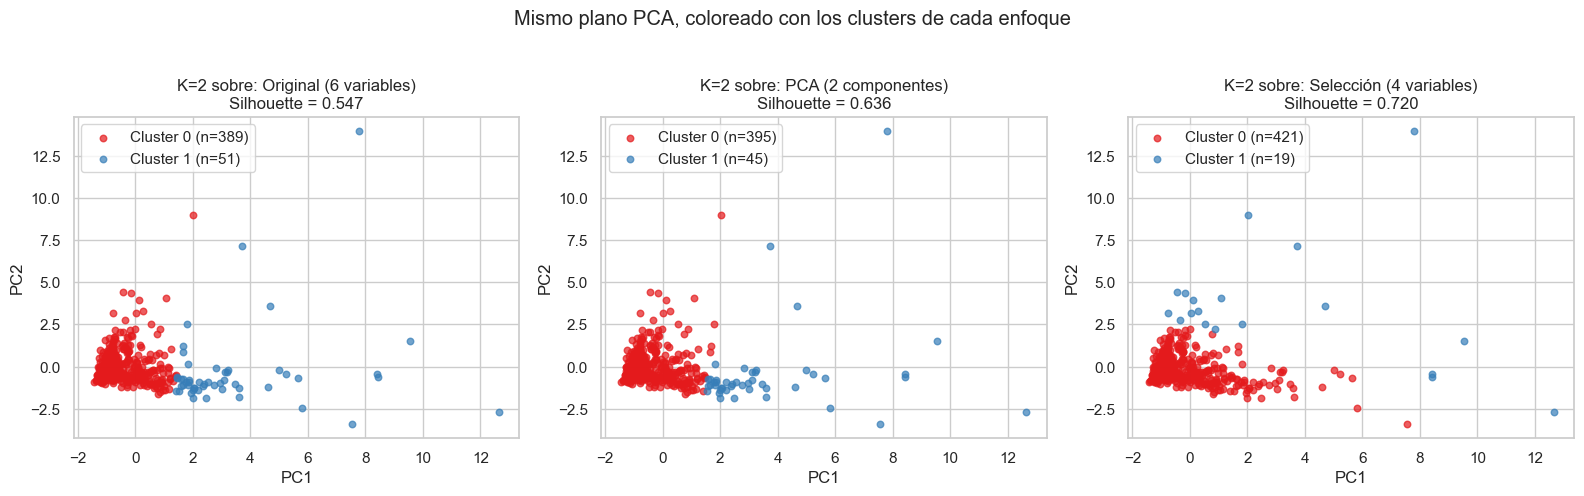

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
pal = sns.color_palette('Set1', 3)
for ax, (name, A) in zip(axes, datasets.items()):
    lab = labels_store[(name, 2)]
    for c in np.unique(lab):
        m = lab == c
        ax.scatter(Z[m, 0], Z[m, 1], s=22, alpha=.7, color=pal[c], label=f'Cluster {c} (n={m.sum()})')
    ax.set_title(f'K=2 sobre: {name}\nSilhouette = {silhouette_score(A, lab):.3f}')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend()
plt.suptitle('Mismo plano PCA, coloreado con los clusters de cada enfoque', y=1.03)
plt.tight_layout(); plt.savefig('figures/07_clusters_k2.png', dpi=150, bbox_inches='tight'); plt.show()

Lo que muestra esta comparación:
- En la selección de variables, K=2 deja un cluster de pocas decenas de clientes (los de gasto extremo en Fresh, Milk, Frozen o Delicassen) y un cluster enorme con todo el resto. El silhouette de 0.72 mide que ese puñado de atípicos está lejos de la masa, no que haya dos segmentos de negocio. Es un resultado engañoso.
- Con PCA y con las variables originales, el cluster minoritario es más grande y tiene una forma coherente: ocupa la zona de PC1 alto, es decir, alto gasto en Grocery, Detergents_Paper y Milk.

### Validación externa con `Channel`

`Channel` no se usó para agrupar, así que sirve como referencia independiente: si los clusters capturan una estructura real del negocio, deberían alinearse con la distinción Horeca (1) vs Retail (2). Es una validación parcial, no una verdad absoluta: los clusters no tienen por qué coincidir con ese canal.

In [14]:
filas = []
for name in datasets:
    lab = labels_store[(name, 2)]
    ct = pd.crosstab(lab, raw['Channel'])
    ct.columns = ['Horeca', 'Retail']
    ct.index = [f'Cluster {i}' for i in ct.index]
    print(name); display(ct)
    # cluster minoritario: % Retail
    menor = np.argmin(np.bincount(lab))
    filas.append({'Enfoque': name,
                  'n cluster minoritario': int((lab == menor).sum()),
                  '% Retail dentro del minoritario': round(100 * (raw.Channel[lab == menor] == 2).mean(), 1),
                  '% de los Retail capturados': round(100 * ((lab == menor) & (raw.Channel == 2)).sum() / (raw.Channel == 2).sum(), 1)})
display(pd.DataFrame(filas).set_index('Enfoque'))

Original (6 variables)


,Horeca,Retail
Cluster 0,293,96
Cluster 1,5,46


PCA (2 componentes)


,Horeca,Retail
Cluster 0,296,99
Cluster 1,2,43


Selección (4 variables)


,Horeca,Retail
Cluster 0,284,137
Cluster 1,14,5


,n cluster minoritario,% Retail dentro del minoritario,% de los Retail capturados
Enfoque,,,
Original (6 variables),51,90.2,32.4
PCA (2 componentes),45,95.6,30.3
Selección (4 variables),19,26.3,3.5


La alineación con `Channel` es mucho más fuerte en PCA (y en las variables originales) que en la selección de variables: el cluster minoritario de PCA está compuesto casi en su totalidad por clientes Retail, mientras que el de la selección contiene muy pocos Retail y es en su mayoría ruido de atípicos. Aun así, ningún enfoque captura a todos los Retail (una parte de ellos tiene un perfil de gasto similar al de Horeca), lo que es una limitación honesta del agrupamiento con estos datos.

### Perfil de los clusters del enfoque elegido (PCA, K=2)

Medias de gasto anual por cluster, en unidades originales, para interpretar los segmentos.

In [15]:
lab_pca2 = labels_store[('PCA (2 componentes)', 2)]
perfil = df.assign(Cluster=lab_pca2).groupby('Cluster').agg(['mean']).round(0)
perfil.columns = [c[0] for c in perfil.columns]
perfil['n'] = np.bincount(lab_pca2)
display(perfil)

perfil_rel = (perfil[vars_all] / df.mean()).round(2)
perfil_rel.columns = [f'{c} (x media)' for c in perfil_rel.columns]
display(perfil_rel)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,n
Cluster,,,,,,,
0,12085.0,4153.0,5595.0,3080.0,1713.0,1310.0,395
1,11257.0,20224.0,28633.0,2997.0,13140.0,3415.0,45


,Fresh (x media),Milk (x media),Grocery (x media),Frozen (x media),Detergents_Paper (x media),Delicassen (x media)
Cluster,,,,,,
0,1.01,0.72,0.7,1.00,0.59,0.86
1,0.94,3.49,3.6,0.98,4.56,2.24


### E.5 Discusión: enfoque más apropiado

Enfoque elegido: PCA con dos componentes y K=2.

Justificación con base en los resultados:
1. Calidad de agrupamiento: en K=2 y K=3 el silhouette con PCA (cerca de 0.63) es claramente superior al de las variables originales en los mismos K, y la estructura es estable entre ambos valores de K.
2. Interpretabilidad: los dos componentes tienen una lectura de negocio clara (PC1 es el eje de comercio minorista; PC2, el de frescos y gastronomía), y los clusters se pueden visualizar directamente en el plano.
3. Validación externa: el cluster minoritario de PCA está compuesto casi totalmente por clientes del canal Retail, algo que ni la selección de variables ni (con la misma nitidez) las variables originales logran.
4. Descarte de la selección de variables: aunque su silhouette en K=2 es el máximo, el resultado proviene de aislar unos pocos clientes extremos, no de encontrar segmentos. Además, eliminar Grocery y Detergents_Paper descarta justo la información que mejor distingue al canal Retail.

Por qué K=2 y no K=3 con PCA: K=3 tiene un silhouette casi igual, pero el tercer cluster tiene apenas 3 clientes, es decir, aísla atípicos y no agrega un segmento útil.

Limitaciones a tener en cuenta:
- Las distribuciones tienen asimetría fuerte y K-means es sensible a atípicos. Una transformación logarítmica antes de estandarizar probablemente mejoraría la separación y sería el siguiente paso natural.
- PCA retiene cerca del 72% de la varianza: el agrupamiento se hace sobre una versión simplificada de los datos.
- Los silhouette de distintos espacios no son estrictamente comparables, por eso se complementó con tamaños de clusters y con la validación externa con `Channel`.
- Dos clusters es una segmentación gruesa: separa a los compradores intensivos en productos de almacén y limpieza del resto, pero no captura matices dentro de Horeca.

## Conclusiones

1. Seis variables de gasto estandarizadas se resumen en dos componentes que explican cerca del 72% de la varianza y tienen una interpretación de negocio clara.
2. Grocery, Detergents_Paper y Milk forman un bloque redundante (correlaciones de 0.66 a 0.92), que es el que construye PC1.
3. K-means funciona mejor sobre el espacio reducido por PCA que sobre las variables originales, y la selección por correlación produce el silhouette más alto pero el menos informativo.
4. La segmentación resultante (K=2) separa un grupo pequeño de alto gasto en almacén, limpieza y lácteos, que corresponde casi por completo al canal Retail, del resto de los clientes.